Exploring Constructed Languages
Class 5 — Data Exploration

In [3]:
%pip install pandas matplotlib

  Using cached matplotlib-3.11.2-cp315-cp315-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached numpy-2.5.4-cp315-cp315-macosx_14_0_arm64.whl.metadata (6.6 kB)
  Using cached contourpy-1.4.0-cp315-cp315-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp315-cp315-macosx_10_15_universal2.whl.metadata (137 kB)
  Using cached kiwisolver-1.5.1-cp315-cp315-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pillow-13.0.0-cp315-cp315-macosx_11_0_arm64.whl.metadata (9.1 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 4.7 MB/s  0:00:024.8 MB/s eta 0:00:0101
Using cached matplotlib-3.11.2-cp315-cp315-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp315-cp315-macosx_11_0_arm64.whl (283 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.67.0-cp315-cp315-macosx_10_15_universal2.whl (3.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

#niceee

In [6]:
df = pd.read_csv("languages/Data.csv", sep=";", encoding="cp1252")

df.head()

,Name,Base Languages,Morphology,Purpose,Year,Location,Author,Age,Speakers,Alphabet,Vowels,Consonants,Structure
0,Solresol,//,ISOL,AUX,1827,France,musician,40.0,0.0,7.0,NaN,NaN,SVO
1,Communicationssprache,"romance, germanic","AGG, FLEX",AUX,1836,Germany,proprietario terriero,75.0,0.0,28.0,8.0,20.0,SVO
2,Universalglot,"romance, germanic",AGG,AUX,1868,France,linguist,55.0,0.0,27.0,7.0,20.0,SVO
3,Volapük,"romance, germanic","AGG, FLEX",AUX,1880,Germany,priest,49.0,25.0,27.0,8.0,19.0,SVO
4,Esperanto,"romance, germanic, slavic",AGG,AUX,1887,Poland,doctor,28.0,2000000.0,28.0,7.0,21.0,SVO


In [7]:
# See how many languages and columns we have
print("Dataset shape:", df.shape)

# See the column names
print("\nColumns:")
print(df.columns.tolist())

Dataset shape: (120, 13)

Columns:
['Name', 'Base Languages', 'Morphology', 'Purpose', 'Year', 'Location', 'Author', 'Age', 'Speakers', 'Alphabet', 'Vowels', 'Consonants', 'Structure']


In [20]:

# I'm curious about WHY people invent languages.
# For me, it was originally for worldbuilding,
# but I know some languages are meant for actual communication.

# value_counts() should tell us how many languages
# belong to each purpose category.

purpose_counts = df["Purpose"].value_counts()

print(purpose_counts)


Purpose
ART      40
AUX      39
ZON      14
ENG      11
CON       7
RIT       7
VIS       1
other     1
Name: count, dtype: int64


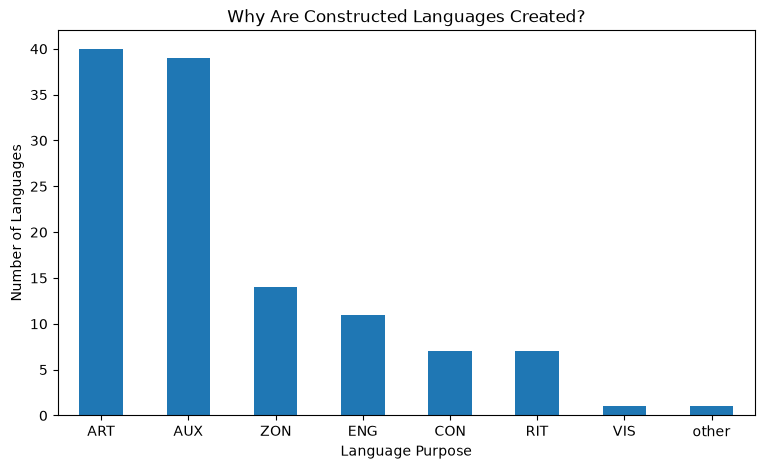

In [9]:

# The numbers are helpful, but I think a graph will make
# comparing the categories a lot easier.

purpose_counts.plot(kind="bar", figsize=(9, 5))

plt.title("Why Are Constructed Languages Created?")
plt.xlabel("Language Purpose")
plt.ylabel("Number of Languages")
plt.xticks(rotation=0)
plt.show()


My observations

I was initially interested in constructed languages because of the Adobe project, where we considered having children discover an alien language. I thought it'd be fun to see how lnaguages are constructed!!!

Looking at the dataset, artistic languages and auxiliary languages are almost equally represented, with 40 and 39 entries respectively. I hadn't really considered how many people invent languages for communication rather than storytelling.

I'm curious whether these different purposes affect how complex or familiar the languages are. Would a language designed to be learned by people have a different structure from one designed for a fictional world?

In [10]:

# Okay, now I want to know WHEN these languages were created.
# I could count each individual year, but with 120 languages
# that might get messy pretty quickly.

# Grouping by century seems easier to read.
# Subtracting 1 before dividing handles century boundaries
# correctly (so 1900 is the 19th century).

df["Century"] = ((df["Year"] - 1) // 100) + 1

century_counts = df["Century"].value_counts().sort_index()

print(century_counts)


Century
11     1
16     3
17     2
19     8
20    77
21    29
Name: count, dtype: int64


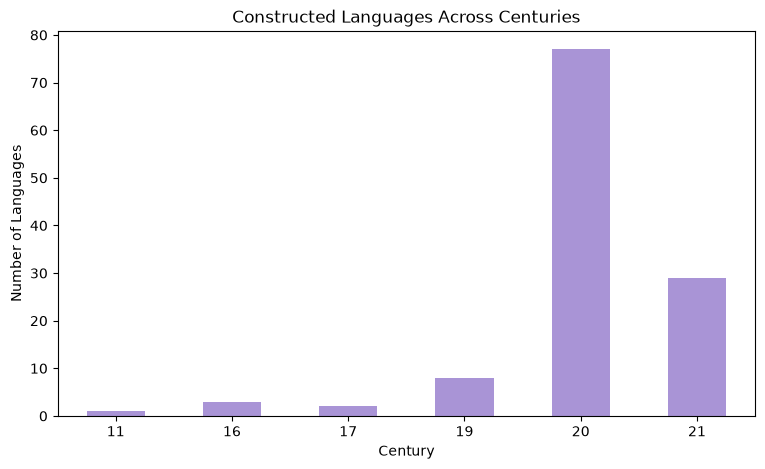

In [11]:

# I used sort_index() above because otherwise value_counts()
# orders things by frequency, not chronologically.

century_counts.plot(
    kind="bar",
    figsize=(9, 5),
    color="#A994D6"
)

plt.title("Constructed Languages Across Centuries")
plt.xlabel("Century")
plt.ylabel("Number of Languages")
plt.xticks(rotation=0)
plt.show()


Structure
SVO    96
SOV     9
VSO     4
OSV     2
OVS     1
VOS     1
Name: count, dtype: int64


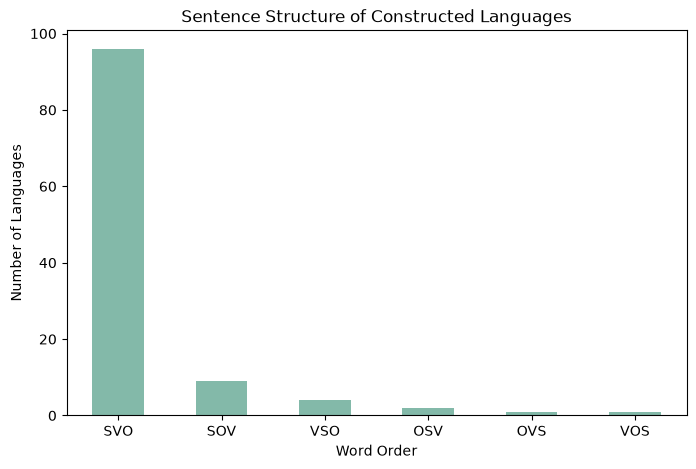

In [12]:

# I was expecting more variety here, especially because
# people can theoretically invent ANY grammatical structure.

# Let's see whether certain sentence structures are
# much more common than others.

structure_counts = df["Structure"].value_counts()

print(structure_counts)

structure_counts.plot(
    kind="bar",
    color="#83B9A9",
    figsize=(8, 5)
)

plt.title("Sentence Structure of Constructed Languages")
plt.xlabel("Word Order")
plt.ylabel("Number of Languages")
plt.xticks(rotation=0)
plt.show()


Structure  OSV  OVS  SOV  SVO  VOS  VSO
Purpose                                
ART          1    1    9   23    1    2
AUX          1    0    0   36    0    0
CON          0    0    0    7    0    0
ENG          0    0    0    9    0    2
RIT          0    0    0    7    0    0
VIS          0    0    0    1    0    0
ZON          0    0    0   12    0    0
other        0    0    0    1    0    0


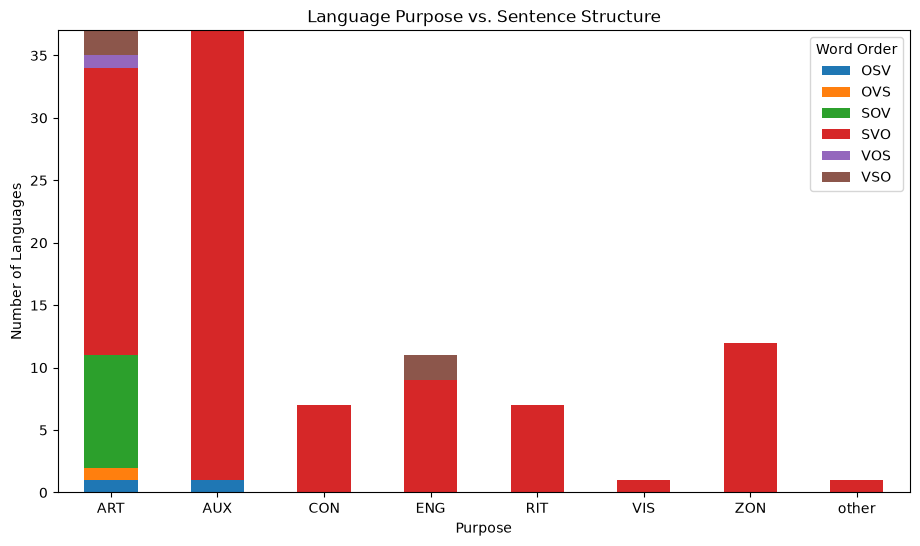

In [13]:

# Now I'm wondering whether artistic languages tend to use
# different sentence structures than auxiliary languages.

# crosstab() is new to me here. From what I understand,
# it counts combinations of two categories.

purpose_structure = pd.crosstab(
    df["Purpose"],
    df["Structure"]
)

print(purpose_structure)

purpose_structure.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Language Purpose vs. Sentence Structure")
plt.xlabel("Purpose")
plt.ylabel("Number of Languages")
plt.xticks(rotation=0)
plt.legend(title="Word Order")
plt.show()


In [14]:
# Okay, I definitely wasn't expecting some of these languages
# to have MILLIONS of speakers.

# I want to see which languages have the largest communities.
# nlargest() seems like a cleaner way to do this than
# trying to sort the entire dataset myself.

most_spoken = df.nlargest(10, "Speakers")

print(most_spoken[["Name", "Purpose", "Speakers"]])

           Name Purpose   Speakers
40        Guosa     ZON  3000000.0
42  Runjakitara     ZON  3000000.0
4     Esperanto     AUX  2000000.0
60       Iyaric     RIT    31000.0
49  Interslavic     ZON    20000.0
19  Interlingua     AUX    10000.0
57  Blissymbols     VIS    10000.0
70    Toki Pona     ENG     5000.0
72       Viossa     ENG     5000.0
62  Medefaidrin     RIT     4000.0


In [15]:

# I'm wondering if a few really popular languages
# are skewing the average.

average_speakers = df["Speakers"].mean()
median_speakers = df["Speakers"].median()

print("Average speakers:", round(average_speakers))
print("Median speakers:", median_speakers)

# Wow, if these numbers are very different...then it's intersting whats going on.


Average speakers: 69131
Median speakers: 0.0


In [16]:

# Okay so now I want to look at the actual design
# of these languages instead of just why they exist.

# I wonder if some invented languages have really
# small alphabets, or if people go completely overboard
# and create a ton of letters.

alphabet_data = df[
    ["Name", "Purpose", "Alphabet"]
].dropna()

# Sorting from largest to smallest
biggest_alphabets = alphabet_data.sort_values(
    "Alphabet",
    ascending=False
)

print("Languages with the largest alphabets:")
display(biggest_alphabets.head(10))

print("Languages with the smallest alphabets:")
display(biggest_alphabets.tail(10))


Languages with the largest alphabets:


,Name,Purpose,Alphabet
30,Poliespo,AUX,54.0
61,Eskayan,RIT,46.0
67,Ithkuil,ENG,40.0
106,Syldavian,ART,37.0
49,Interslavic,ZON,36.0
88,D'ni,ART,35.0
91,Teonaht,ART,35.0
109,Spocanian,ART,34.0
63,Damin,RIT,34.0
103,Romulan,ART,34.0


Languages with the smallest alphabets:


,Name,Purpose,Alphabet
86,Tsolyáni,ART,20.0
5,Mundolinco,AUX,20.0
6,Bolak,AUX,19.0
21,Lingua sistemfrater,AUX,18.0
68,Láadan,ENG,15.0
70,Toki Pona,ENG,14.0
12,Timerio,AUX,10.0
96,Moss,ART,7.0
0,Solresol,AUX,7.0
73,Lincos,other,2.0


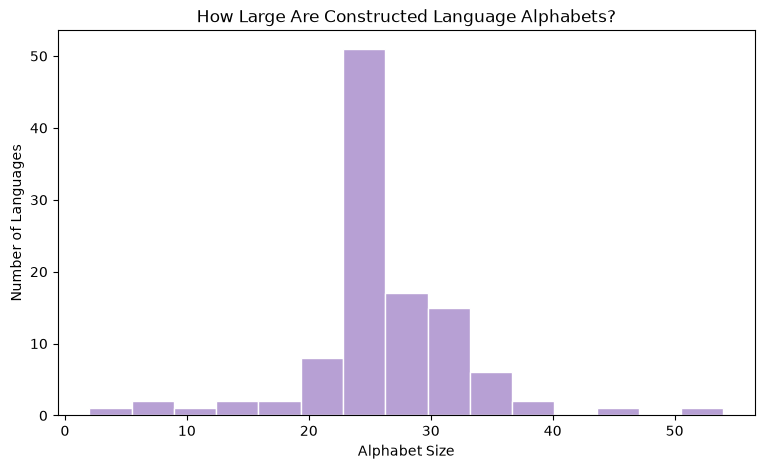

In [17]:

# I haven't used a histogram yet!
#probably should 
df["Alphabet"].plot(
    kind="hist",
    bins=15,
    figsize=(9, 5),
    color="#B7A0D4",
    edgecolor="white"
)

plt.title("How Large Are Constructed Language Alphabets?")
plt.xlabel("Alphabet Size")
plt.ylabel("Number of Languages")
plt.show()


In [18]:

#making new things + another column because why not
df["Vowel Ratio"] = (
    df["Vowels"] / df["Alphabet"]
) * 100

vowel_heavy = df[
    ["Name", "Vowels", "Consonants", "Vowel Ratio"]
].sort_values(
    "Vowel Ratio",
    ascending=False
)

display(vowel_heavy.head(10))


,Name,Vowels,Consonants,Vowel Ratio
100,Dothraki,23.0,4.0,85.185185
71,K?len,16.0,17.0,48.484848
112,Baronh,12.0,16.0,42.857143
30,Poliespo,22.0,32.0,40.740741
83,Barsoomian,10.0,15.0,40.000000
80,Atlantean,10.0,15.0,40.000000
66,aUI,12.0,19.0,38.709677
99,Valyrian,12.0,21.0,36.363636
78,Khuzdul,12.0,21.0,36.363636
70,Toki Pona,5.0,9.0,35.714286
